The data source from kaggle : 'https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset/data'

In [1]:
!gdown --fuzzy "https://docs.google.com/spreadsheets/d/1h4wC2ToIrHMBivQJnAv11vmM30GvbgYR/edit?usp=drive_link&ouid=107601406666702777691&rtpof=true&sd=true" -O data.xlsx

Downloading...
From: https://drive.google.com/uc?id=1h4wC2ToIrHMBivQJnAv11vmM30GvbgYR
To: /content/data.xlsx
100% 1.37M/1.37M [00:00<00:00, 67.4MB/s]


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
raw = pd.read_excel('/content/data.xlsx')
raw.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [4]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [5]:
raw['Total Charges'] = pd.to_numeric(raw['Total Charges'], errors='coerce')

In [6]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Count,7043.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Zip Code,7043.0,93521.964646,1865.794555,90001.000000,92102.000000,93552.000000,95351.000000,96161.000000
Latitude,7043.0,36.282441,2.455723,32.555828,34.030915,36.391777,38.224869,41.962127
Longitude,7043.0,-119.798880,2.157889,-124.301372,-121.815412,-119.730885,-118.043237,-114.192901
Tenure Months,7043.0,32.371149,24.559481,0.000000,9.000000,29.000000,55.000000,72.000000
Monthly Charges,7043.0,64.761692,30.090047,18.250000,35.500000,70.350000,89.850000,118.750000
Total Charges,7032.0,2283.300441,2266.771362,18.800000,401.450000,1397.475000,3794.737500,8684.800000
Churn Value,7043.0,0.265370,0.441561,0.000000,0.000000,0.000000,1.000000,1.000000
Churn Score,7043.0,58.699418,21.525131,5.000000,40.000000,61.000000,75.000000,100.000000
CLTV,7043.0,4400.295755,1183.057152,2003.000000,3469.000000,4527.000000,5380.500000,6500.000000


In [7]:
raw.describe(include='object').T

,count,unique,top,freq
CustomerID,7043,7043,3668-QPYBK,1
Country,7043,1,United States,7043
State,7043,1,California,7043
City,7043,1129,Los Angeles,305
Lat Long,7043,1652,"34.159534, -116.425984",5
Gender,7043,2,Male,3555
Senior Citizen,7043,2,No,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,5416
Phone Service,7043,2,Yes,6361


In [8]:
# Analysis preparation

feature_columns = [
    'Gender', 'Senior Citizen', 'Partner', 'Dependents',
    'Tenure Months', 'Phone Service', 'Multiple Lines',
    'Internet Service', 'Online Security', 'Online Backup',
    'Device Protection', 'Tech Support', 'Streaming TV',
    'Streaming Movies', 'Contract', 'Paperless Billing',
    'Payment Method', 'Monthly Charges', 'Total Charges'
]

X = raw[feature_columns].copy()
X.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30


In [9]:
for col in X.columns:
    print(f"Unique values in '{col}':")
    print(X[col].unique())
    print("-" * 40)

Unique values in 'Gender':
['Male' 'Female']
----------------------------------------
Unique values in 'Senior Citizen':
['No' 'Yes']
----------------------------------------
Unique values in 'Partner':
['No' 'Yes']
----------------------------------------
Unique values in 'Dependents':
['No' 'Yes']
----------------------------------------
Unique values in 'Tenure Months':
[ 2  8 28 49 10  1 47 17  5 34 11 15 18  9  7 12 25 68 55 37  3 27 20  4
 58 53 13  6 19 59 16 52 24 32 38 54 43 63 21 69 22 61 60 48 40 23 39 35
 56 65 33 30 45 46 62 70 50 44 71 26 14 41 66 64 29 42 67 51 31 57 36 72
  0]
----------------------------------------
Unique values in 'Phone Service':
['Yes' 'No']
----------------------------------------
Unique values in 'Multiple Lines':
['No' 'Yes' 'No phone service']
----------------------------------------
Unique values in 'Internet Service':
['DSL' 'Fiber optic' 'No']
----------------------------------------
Unique values in 'Online Security':
['Yes' 'No' 'No intern

In [10]:
# Replace 'No phone service' and 'No internet service' with 'No' in DataFrame X
X = X.replace(['No phone service', 'No internet service'], 'No')


# Verify the changes by printing unique values for columns that had those values
for col in ['Multiple Lines', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies']:
    print(f"Unique values in '{col}': {X[col].unique()}")

Unique values in 'Multiple Lines': ['No' 'Yes']
Unique values in 'Online Security': ['Yes' 'No']
Unique values in 'Online Backup': ['Yes' 'No']
Unique values in 'Device Protection': ['No' 'Yes']
Unique values in 'Tech Support': ['No' 'Yes']
Unique values in 'Streaming TV': ['No' 'Yes']
Unique values in 'Streaming Movies': ['No' 'Yes']


In [11]:
X.isna().sum()

,0
Gender,0
Senior Citizen,0
Partner,0
Dependents,0
Tenure Months,0
Phone Service,0
Multiple Lines,0
Internet Service,0
Online Security,0
Online Backup,0


In [12]:
# for machine learning

y = raw['Churn Label'].str.strip().map({'No': 0, 'Yes': 1})
y.head()

,Churn Label
0,1
1,1
2,1
3,1
4,1


In [13]:
analysis = pd.concat([X, y], axis=1)
analysis.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,1


In [14]:
analysis['Churn Reason'] = raw['Churn Reason']
analysis.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,...,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Reason
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,Competitor made better offer
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,Moved
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,...,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1,Moved
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1,Moved
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,1,Competitor had better devices


In [15]:
analysis['Churn Label'] = analysis['Churn Label'].map({0: 'Stay', 1: 'Churn'})
analysis.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,...,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Reason
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Churn,Competitor made better offer
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Churn,Moved
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,...,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Churn,Moved
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Churn,Moved
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Churn,Competitor had better devices


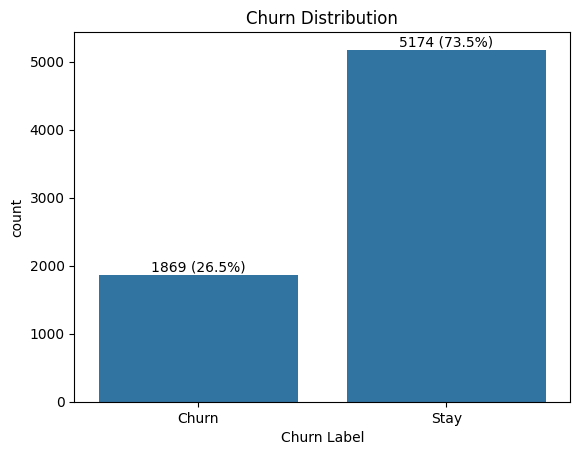

,proportion
Churn Label,
Stay,0.73463
Churn,0.26537


In [16]:
ax = sns.countplot(x='Churn Label', data=analysis)
total = len(analysis)
for p in ax.patches:
    count = int(p.get_height())
    ax.annotate(f'{count} ({100*count/total:.1f}%)',
                (p.get_x()+p.get_width()/2., count), ha='center', va='bottom')
plt.title('Churn Distribution')
plt.show()

analysis['Churn Label'].value_counts(normalize=True)

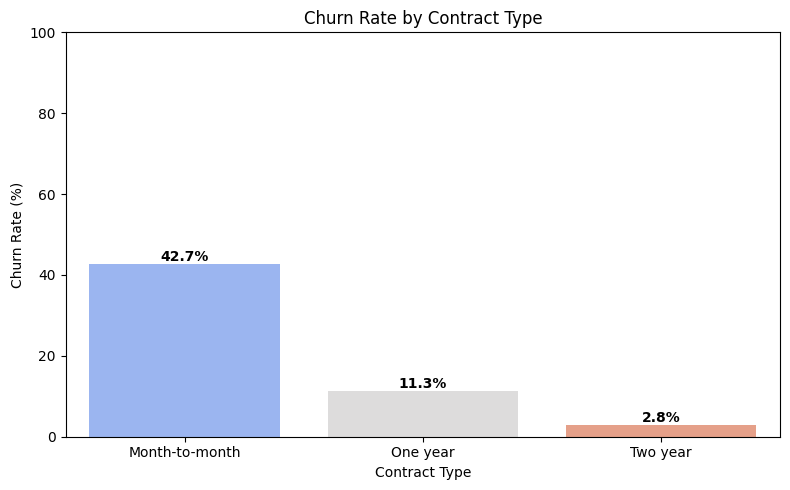

In [17]:
# Calculate the churn rate by Contract type from the analysis dataframe
contract_churn = analysis.groupby('Contract')['Churn Label'].value_counts(normalize=True).unstack().fillna(0)
contract_churn['Churn Rate (%)'] = contract_churn['Churn'] * 100
contract_churn = contract_churn.reset_index()

# Visualize Churn Rate by Contract
plt.figure(figsize=(8, 5))
ax = sns.barplot(x='Contract', y='Churn Rate (%)', data=contract_churn, palette='coolwarm', hue='Contract', legend=False)

# Annotate the exact percentages on top of each bar
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Churn Rate by Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Contract Type')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

/tmp/ipykernel_786/838569523.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


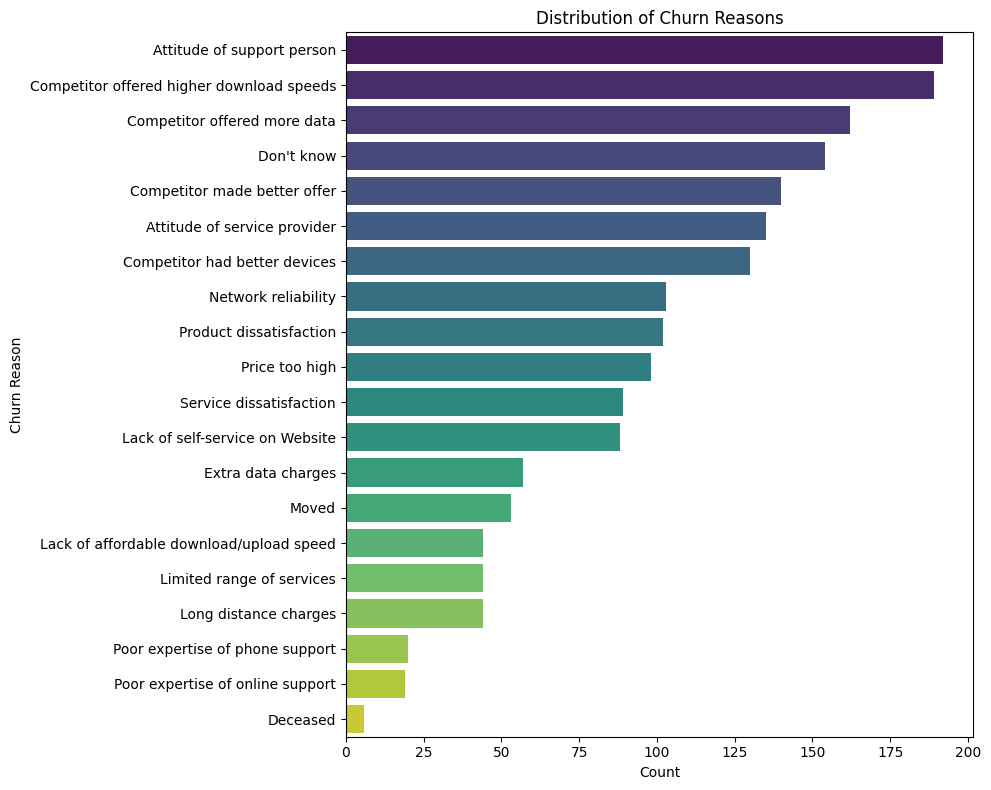

In [18]:
plt.figure(figsize=(10, 8))
sns.countplot(
    y='Churn Reason',
    data=analysis,
    order=analysis['Churn Reason'].value_counts().index,
    palette='viridis'
)
plt.title('Distribution of Churn Reasons')
plt.xlabel('Count')
plt.ylabel('Churn Reason')
plt.tight_layout()
plt.show()

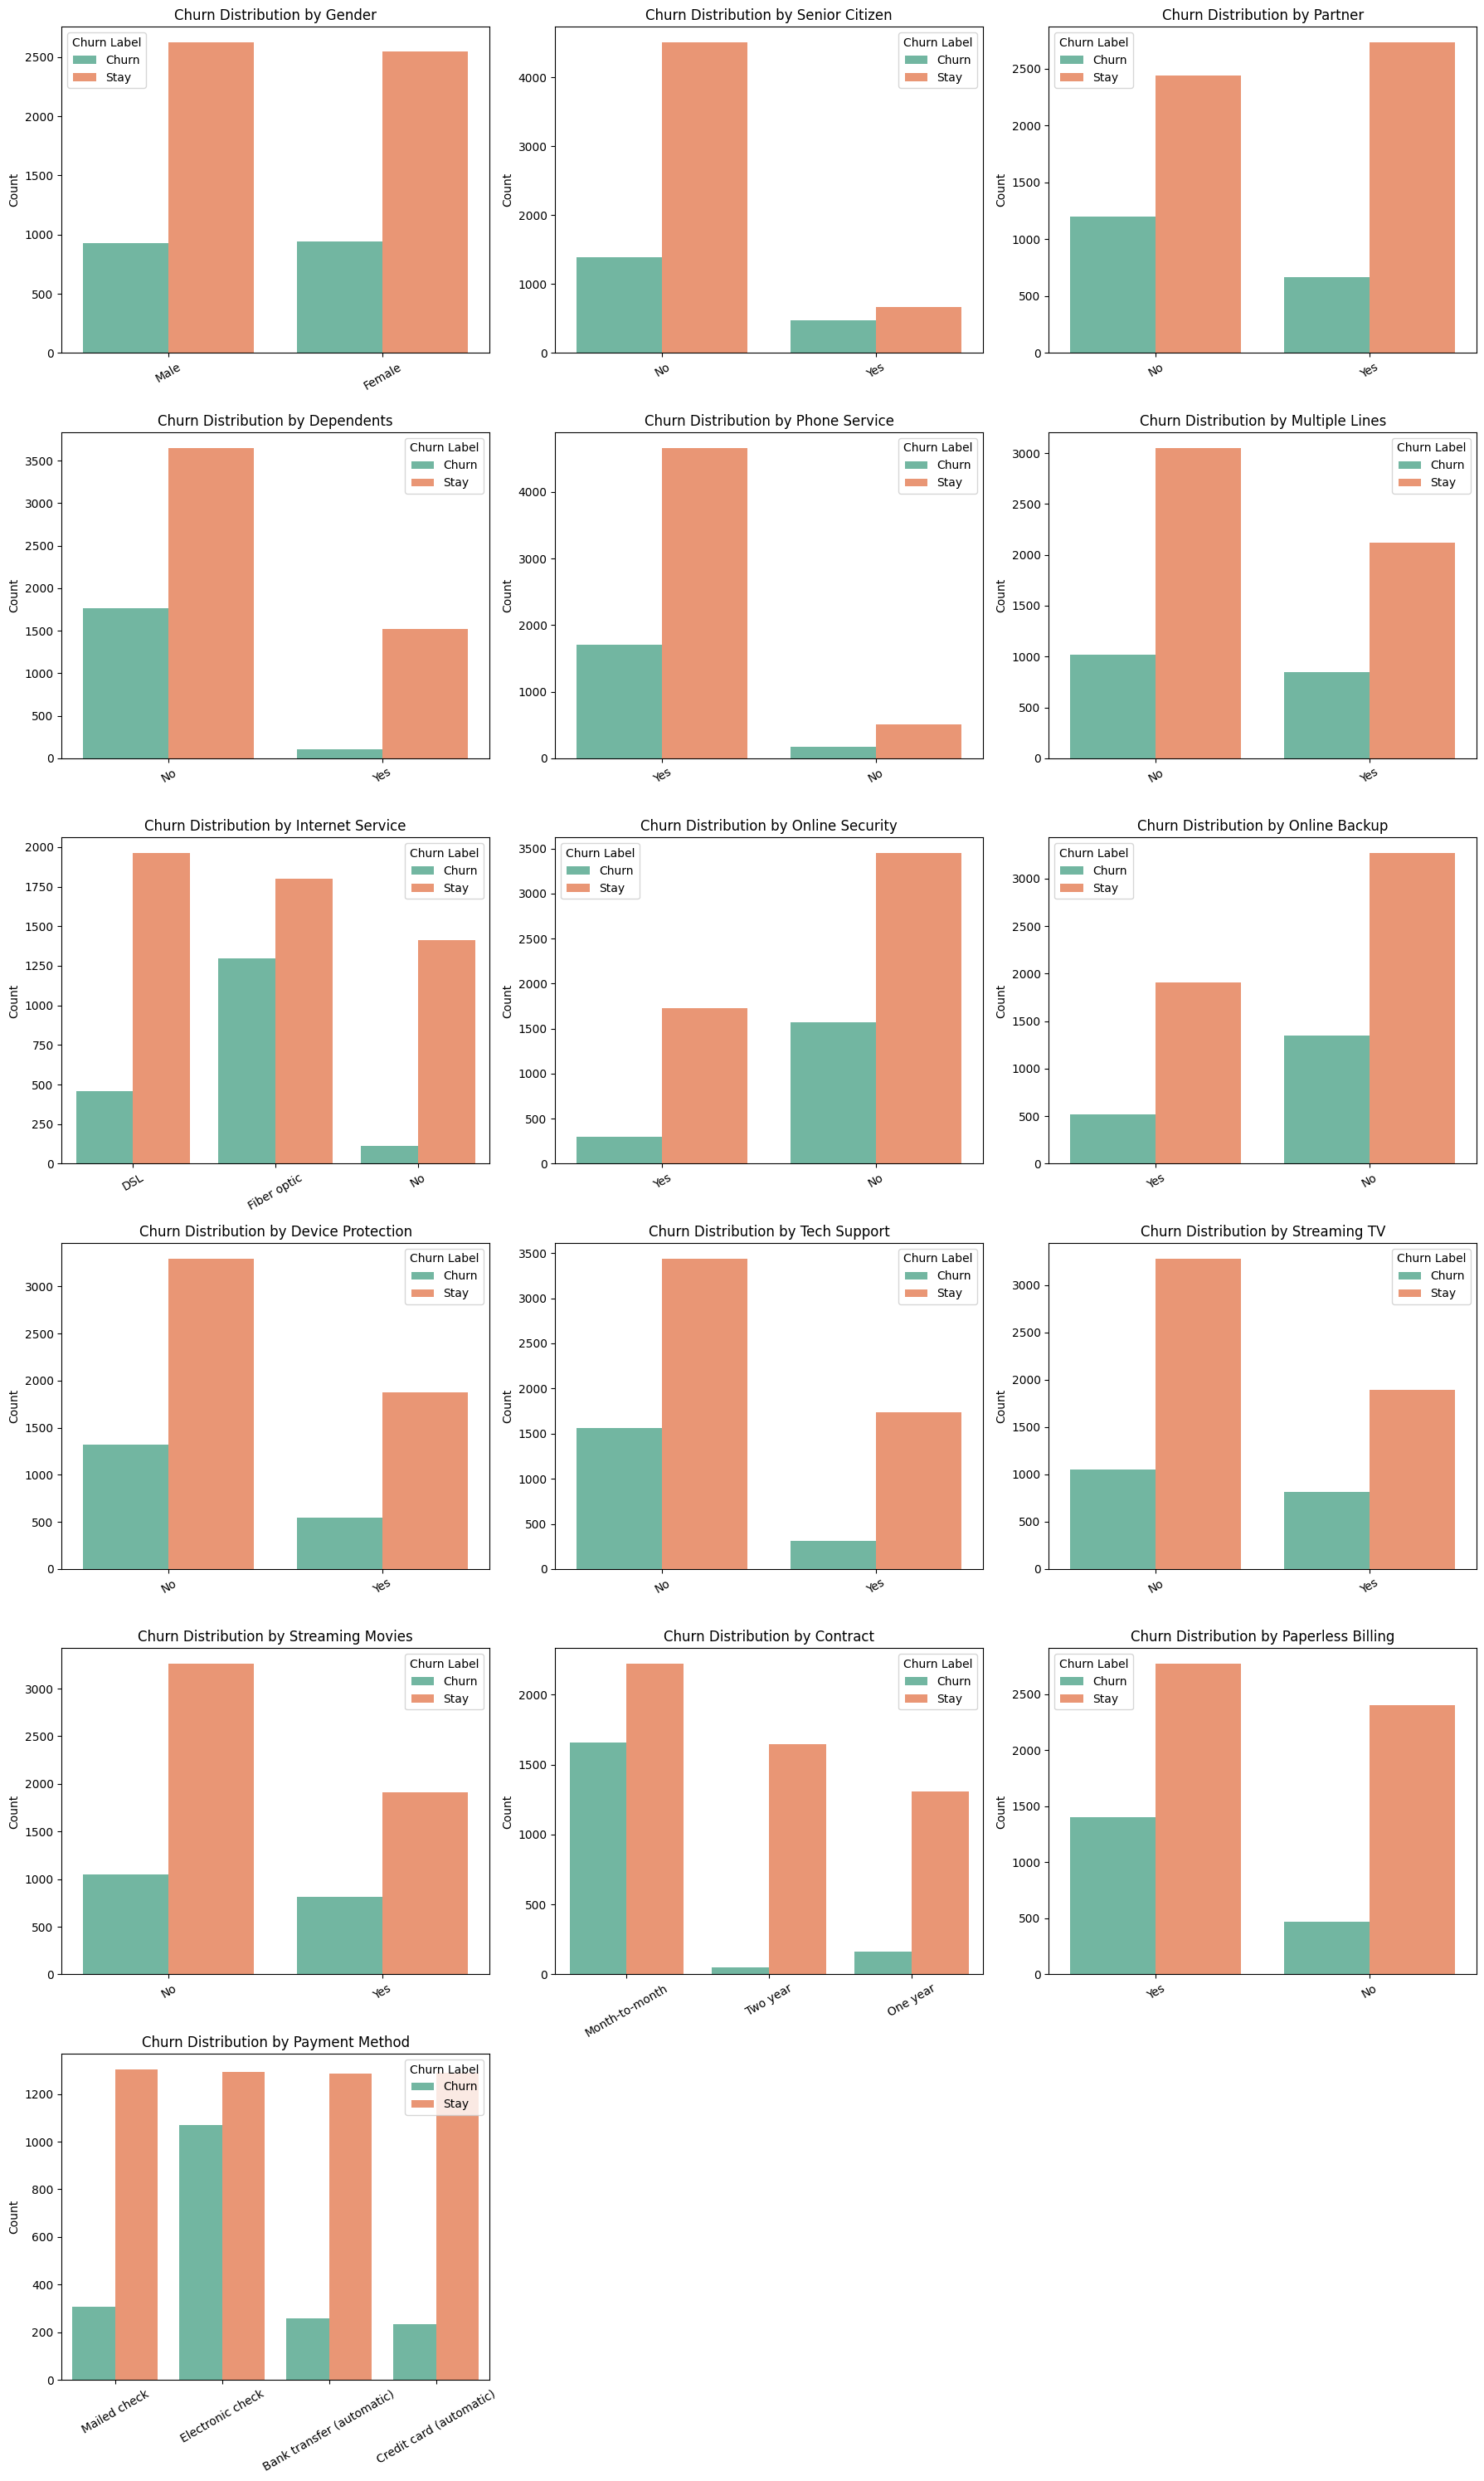

In [19]:
import math

# Identify categorical columns excluding 'Churn Reason'
categorical_cols = [col for col in X.columns if X[col].dtype == 'object']

# Determine grid layout
num_cols = 3
num_rows = math.ceil(len(categorical_cols) / num_cols)

fig, axes = plt.subplots(num_rows, num_cols, figsize=(18, 5 * num_rows))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(
        x=col,
        hue='Churn Label',
        data=analysis,
        ax=axes[i],
        palette='Set2'
    )
    axes[i].set_title(f'Churn Distribution by {col}')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=30)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

/tmp/ipykernel_786/530462431.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn Label', y='Tenure Months', data=analysis, palette='Set2')


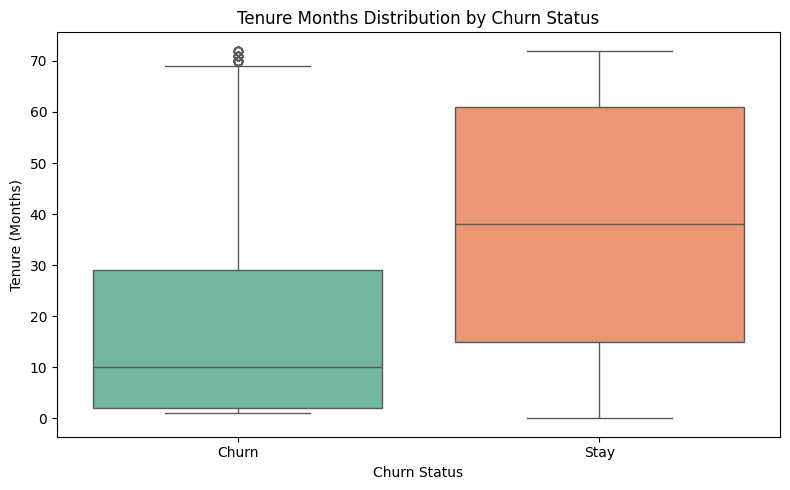

In [20]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Churn Label', y='Tenure Months', data=analysis, palette='Set2')
plt.title('Tenure Months Distribution by Churn Status')
plt.xlabel('Churn Status')
plt.ylabel('Tenure (Months)')
plt.tight_layout()
plt.show()

/tmp/ipykernel_786/1200226441.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn Label', y='Monthly Charges', data=analysis, palette='Set2')


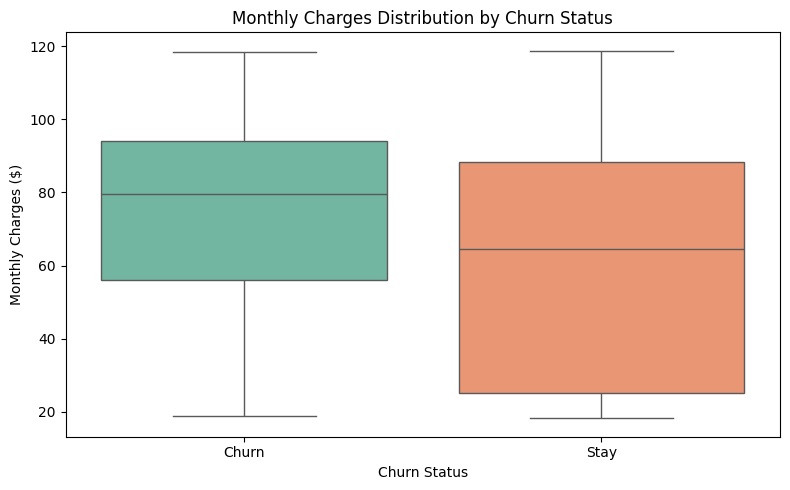

In [21]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Churn Label', y='Monthly Charges', data=analysis, palette='Set2')
plt.title('Monthly Charges Distribution by Churn Status')
plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges ($)')
plt.tight_layout()
plt.show()

/tmp/ipykernel_786/917526917.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn Label', y='Total Charges', data=analysis, palette='Set2')


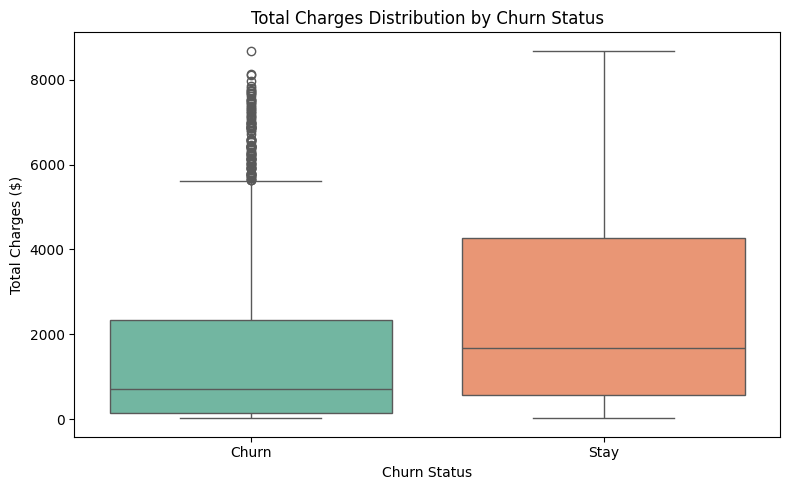

In [22]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Churn Label', y='Total Charges', data=analysis, palette='Set2')
plt.title('Total Charges Distribution by Churn Status')
plt.xlabel('Churn Status')
plt.ylabel('Total Charges ($)')
plt.tight_layout()
plt.show()

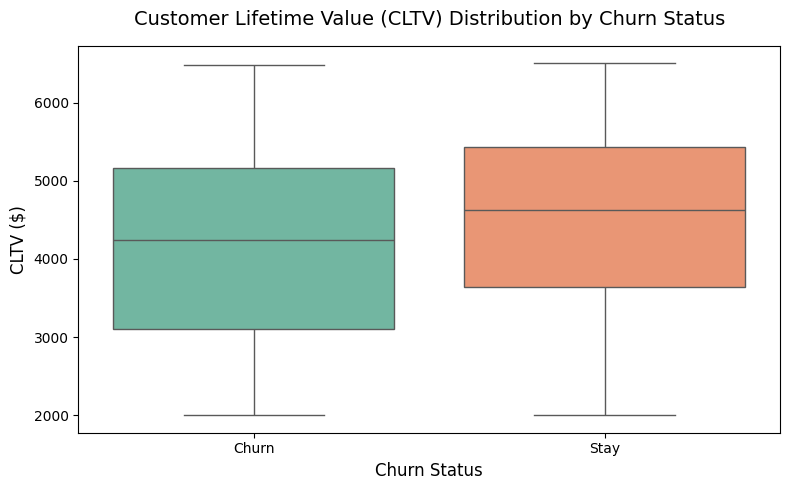

In [59]:
import seaborn as sns
import matplotlib.pyplot as plt

# Ensure the CLTV column exists in our analysis DataFrame for plotting
analysis['CLTV'] = raw['CLTV']

# Create a boxplot to compare CLTV distribution between customers who Churn vs Stay
plt.figure(figsize=(8, 5))
sns.boxplot(x='Churn Label', y='CLTV', data=analysis, palette='Set2', hue='Churn Label', legend=False)

plt.title('Customer Lifetime Value (CLTV) Distribution by Churn Status', fontsize=14, pad=15)
plt.xlabel('Churn Status', fontsize=12)
plt.ylabel('CLTV ($)', fontsize=12)
plt.tight_layout()
plt.show()

In [23]:
# for machine learning

features = X.copy()
features.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30


In [24]:
label = y.copy()
label.head()

,Churn Label
0,1
1,1
2,1
3,1
4,1


In [25]:
# Map 'Yes' -> 1, 'No' -> 0 and 'Female' -> 1, 'Male' -> 0
features = features.replace({'Yes': 1, 'No': 0, 'Female': 1, 'Male': 0})

# Display first few rows to verify transformation
display(features.head())

/tmp/ipykernel_786/1057469571.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  features = features.replace({'Yes': 1, 'No': 0, 'Female': 1, 'Male': 0})


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges
0,0,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15
1,1,0,0,1,2,1,0,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65
2,1,0,0,1,8,1,1,Fiber optic,0,0,1,0,1,1,Month-to-month,1,Electronic check,99.65,820.50
3,1,0,1,1,28,1,1,Fiber optic,0,0,1,1,1,1,Month-to-month,1,Electronic check,104.80,3046.05
4,0,0,0,1,49,1,1,Fiber optic,0,1,1,0,1,1,Month-to-month,1,Bank transfer (automatic),103.70,5036.30


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(features, label, test_size=0.2, random_state=42, stratify=label)

In [27]:
total_samples = len(features)
train_count = len(X_train)
test_count = len(X_test)

train_pct = (train_count / total_samples) * 100
test_pct = (test_count / total_samples) * 100

print(f"Total dataset size: {total_samples}")
print(f"Train set size:    {train_count} ({train_pct:.2f}%)")
print(f"Test set size:     {test_count} ({test_pct:.2f}%)")

Total dataset size: 7043
Train set size:    5634 (79.99%)
Test set size:     1409 (20.01%)


In [28]:
# Calculate value counts and percentages for y_train and y_test
train_counts = y_train.value_counts()
train_pcts = y_train.value_counts(normalize=True) * 100

test_counts = y_test.value_counts()
test_pcts = y_test.value_counts(normalize=True) * 100

# Display the distributions side by side
dist_df = pd.DataFrame({
    'Train Count': train_counts,
    'Train %': train_pcts,
    'Test Count': test_counts,
    'Test %': test_pcts
})

print("Churn Label Distribution (0 = Stay, 1 = Churn):")
display(dist_df)

Churn Label Distribution (0 = Stay, 1 = Churn):


,Train Count,Train %,Test Count,Test %
Churn Label,,,,
0,4139,73.464679,1035,73.456352
1,1495,26.535321,374,26.543648


In [29]:
dup_mask = X_train.duplicated()
print('Duplicated data on Train:', int(dup_mask.sum()))
X_train, y_train = X_train[~dup_mask], y_train[~dup_mask]
print('After dropping duplicated data:', X_train.shape)

Duplicated data on Train: 26
After dropping duplicated data: (5608, 19)


In [36]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.compose import ColumnTransformer

RANDOM_STATE = 42

numeric_features = ['Tenure Months', 'Monthly Charges', 'Total Charges']
target_enc_features = ['Internet Service', 'Contract', 'Payment Method']
binary_features = ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
                   'Multiple Lines', 'Online Security', 'Online Backup', 'Device Protection',
                   'Tech Support', 'Streaming TV', 'Streaming Movies', 'Paperless Billing']

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('te', TargetEncoder(target_type='binary', random_state=RANDOM_STATE), target_enc_features),
    ('bin', 'passthrough', binary_features),
], remainder='drop')

preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Tenure Months', 'Monthly Charges',
                                  'Total Charges']),
                                ('te',
                                 TargetEncoder(random_state=42,
                                               target_type='binary'),
                                 ['Internet Service', 'Contract',
                                  'Payment Method']),
                                ('bin', 'passthrough',
                                 ['Gender', 'Senior Citizen', 'Partner',
                                  'Dependents', 'Phone Service',
                                  'Multiple Lines', 'Online Security',
                                  'Online Backup', 'Device Protection',
                                  'Tech Support', 'Streaming TV',
                                  'Streaming Movies', 'Paperless Billing'])])

In [39]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'KNN':                  KNeighborsClassifier(),
    'Decision Tree':        DecisionTreeClassifier(random_state=RANDOM_STATE),
    'SVM (RBF)':            SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE),
}

def build_pipeline(model):
    return ImbPipeline([
        ('prep', preprocessor),
        ('clf', model),
    ])

In [47]:
# Cast target-encoded columns to string to ensure uniform type
for col in target_enc_features:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

fitted = {}
for name, model in models.items():
    pipe = build_pipeline(model).fit(X_train, y_train)
    fitted[name] = pipe
    print(f'{name} -> Trained')

Logistic Regression -> Trained
KNN -> Trained
Decision Tree -> Trained
SVM (RBF) -> Trained


In [48]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

def evaluate(name, pipe):
    rows = []
    for split, Xs, ys in [('Train', X_train, y_train), ('Test', X_test, y_test)]:
        pred = pipe.predict(Xs)
        tn, fp, fn, tp = confusion_matrix(ys, pred).ravel()
        rows.append({
            'split': split, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'accuracy': round(accuracy_score(ys, pred), 3),
            'precision': round(precision_score(ys, pred, zero_division=0), 3),
            'recall': round(recall_score(ys, pred, zero_division=0), 3),
            'f1': round(f1_score(ys, pred, zero_division=0), 3),
        })
    print(f'===== {name} =====')
    display(pd.DataFrame(rows).set_index('split'))

In [49]:
for name, pipe in fitted.items():
    evaluate(name, pipe)

===== Logistic Regression =====


,TP,FP,FN,TN,accuracy,precision,recall,f1
split,,,,,,,,
Train,862,428,620,3698,0.813,0.668,0.582,0.622
Test,215,114,159,921,0.806,0.653,0.575,0.612


===== KNN =====


,TP,FP,FN,TN,accuracy,precision,recall,f1
split,,,,,,,,
Train,994,353,488,3773,0.850,0.738,0.671,0.703
Test,202,151,172,884,0.771,0.572,0.540,0.556


===== Decision Tree =====


,TP,FP,FN,TN,accuracy,precision,recall,f1
split,,,,,,,,
Train,1295,197,187,3929,0.932,0.868,0.874,0.871
Test,207,185,167,850,0.750,0.528,0.553,0.540


===== SVM (RBF) =====


,TP,FP,FN,TN,accuracy,precision,recall,f1
split,,,,,,,,
Train,783,282,699,3844,0.825,0.735,0.528,0.615
Test,182,86,192,949,0.803,0.679,0.487,0.567


In [50]:
from sklearn.metrics import average_precision_score, roc_auc_score
summary = []
for name, pipe in fitted.items():
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    summary.append({
        'model': name,
        'recall_test': round(recall_score(y_test, pred, zero_division=0), 3),
        'precision_test': round(precision_score(y_test, pred, zero_division=0), 3),
        'f1_test': round(f1_score(y_test, pred, zero_division=0), 3),
        'roc_auc': round(roc_auc_score(y_test, proba), 3),
        'pr_auc': round(average_precision_score(y_test, proba), 3),
    })
pd.DataFrame(summary).sort_values('f1_test', ascending=False).reset_index(drop=True)

,model,recall_test,precision_test,f1_test,roc_auc,pr_auc
0,Logistic Regression,0.575,0.653,0.612,0.849,0.647
1,SVM (RBF),0.487,0.679,0.567,0.817,0.647
2,KNN,0.540,0.572,0.556,0.789,0.543
3,Decision Tree,0.553,0.528,0.540,0.687,0.411


In [51]:
from sklearn.metrics import classification_report

best_name = 'Logistic Regression'
best_model = fitted[best_name]
y_pred = best_model.predict(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f'Best Model: {best_name}')
print(f'TP={tp}  FP={fp}  FN={fn}  TN={tn}')
print(classification_report(y_test, y_pred, digits=3))

Best Model: Logistic Regression
TP=215  FP=114  FN=159  TN=921
              precision    recall  f1-score   support

           0      0.853     0.890     0.871      1035
           1      0.653     0.575     0.612       374

    accuracy                          0.806      1409
   macro avg      0.753     0.732     0.741      1409
weighted avg      0.800     0.806     0.802      1409



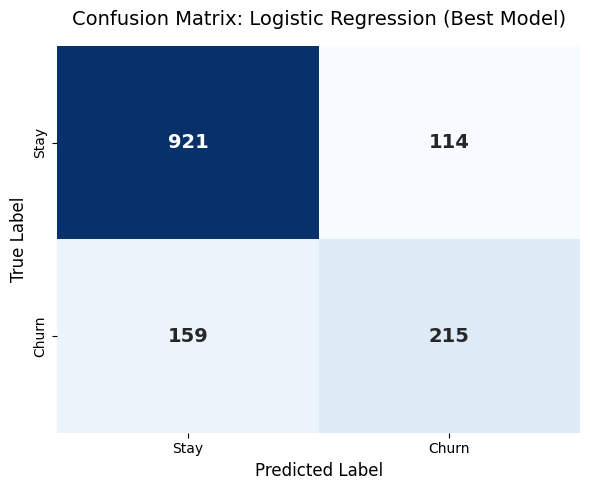

In [52]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Compute the confusion matrix for the best model (Logistic Regression)
cm = confusion_matrix(y_test, y_pred)

# Define the labels for our classes
class_names = ['Stay', 'Churn']

# Create the heatmap plot
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            cbar=False, annot_kws={'size': 14, 'weight': 'bold'})

plt.title('Confusion Matrix: Logistic Regression (Best Model)', fontsize=14, pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

In [57]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix

# Extract confusion matrix parameters from our best Logistic Regression model
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

# --- Business Assumptions ---
# Let's define the business economics of our customer retention program:
average_cltv = 4400      # Average Customer Lifetime Value (from raw['CLTV'].mean())
retention_offer = 150    # Cost of the incentive offered to at-risk customers (e.g., discounts, free upgrades)
acceptance_rate = 0.60   # Probability that a churn-flagged customer accepts the offer and stays

# --- Business Metric Calculations ---
# 1. Total Cost of Inaction (Cost of ignoring churn entirely)
# If we do nothing, all actual churners (TP + FN) leave.
total_churners = tp + fn
cost_of_inaction = total_churners * average_cltv

# 2. Cost of the Retention Campaign
# We target anyone the model predicts will churn (TP + FP)
targeted_campaigns = tp + fp
campaign_cost = targeted_campaigns * retention_offer

# 3. Revenue Saved from Rescued Customers
# Only those who actually intended to leave (TP) and accept our offer are saved.
rescued_customers = tp * acceptance_rate
revenue_saved = rescued_customers * average_cltv

# 4. Financial Waste (Cost of targeting False Positives)
# We spend offer costs on people who were never going to leave anyway (FP)
wasted_spend = fp * retention_offer

# 5. Net Savings (Value generated by using the model)
net_savings = revenue_saved - campaign_cost

# 6. Return on Investment (ROI) of the retention campaign
roi = (net_savings / campaign_cost) * 100

# Create a structured Business Report
business_metrics = {
    "Metric Description": [
        "Customers Evaluated",
        "True Churners Correctly Flagged (TP)",
        "False Alarms Targeted (FP)",
        "Missed Churners (FN)",
        "Estimated Average Customer Value (CLTV)",
        "Retention Offer Cost per Customer",
        "Retention Offer Acceptance Rate",
        "Cost of No Retention Campaign (Loss of all actual churners)",
        "Cost to Run Retention Campaign (Incentives Offered)",
        "Wasted Marketing Spend on Loyal Customers (FP)",
        "Customers Successfully Rescued",
        "Revenue Saved from Rescued Customers",
        "Net Business Savings (Profit Improvement)",
        "Campaign Return on Investment (ROI)"
    ],
    "Value": [
        len(y_test),
        f"{tp} customers",
        f"{fp} customers",
        f"{fn} customers",
        f"${average_cltv:,.2f}",
        f"${retention_offer:,.2f}",
        f"{acceptance_rate * 100:.0f}%",
        f"${cost_of_inaction:,.2f}",
        f"${campaign_cost:,.2f}",
        f"${wasted_spend:,.2f}",
        f"{rescued_customers:.1f} customers",
        f"${revenue_saved:,.2f}",
        f"${net_savings:,.2f}",
        f"{roi:.2f}%"
    ]
}

business_report_df = pd.DataFrame(business_metrics)
pd.set_option('display.max_colwidth', None)
display(business_report_df)

,Metric Description,Value
0,Customers Evaluated,1409
1,True Churners Correctly Flagged (TP),215 customers
2,False Alarms Targeted (FP),114 customers
3,Missed Churners (FN),159 customers
4,Estimated Average Customer Value (CLTV),"$4,400.00"
5,Retention Offer Cost per Customer,$150.00
6,Retention Offer Acceptance Rate,60%
7,Cost of No Retention Campaign (Loss of all actual churners),"$1,645,600.00"
8,Cost to Run Retention Campaign (Incentives Offered),"$49,350.00"
9,Wasted Marketing Spend on Loyal Customers (FP),"$17,100.00"


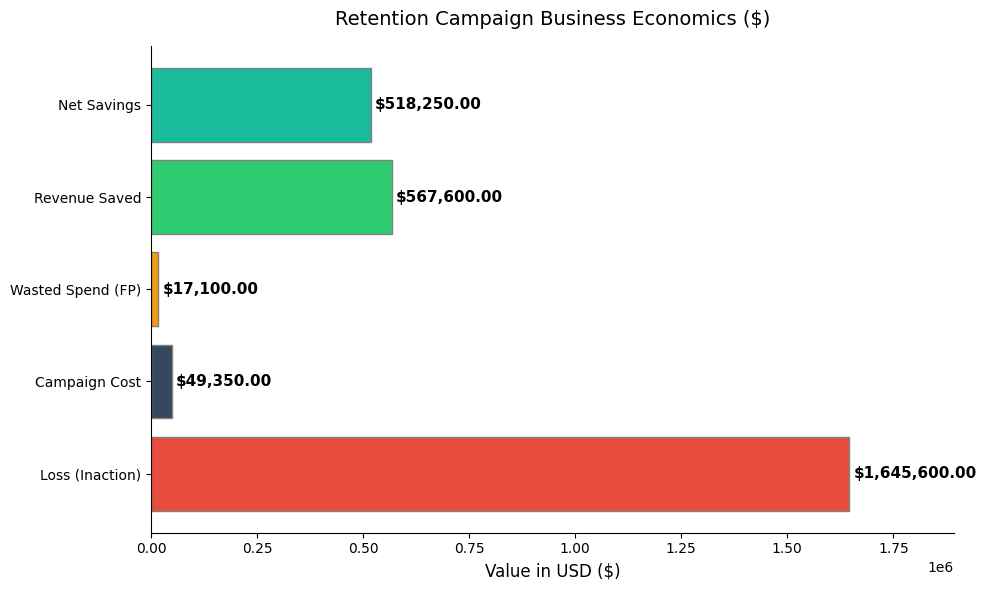

In [62]:
# Extract key metrics for visualization
financial_labels = [
    'Loss (Inaction)',
    'Campaign Cost',
    'Wasted Spend (FP)',
    'Revenue Saved',
    'Net Savings'
]

financial_values = [
    total_churners * average_cltv,
    campaign_cost,
    wasted_spend,
    revenue_saved,
    net_savings
]

# Create a bar chart
plt.figure(figsize=(10, 6))
colors = ['#e74c3c', '#34495e', '#f39c12', '#2ecc71', '#1abc9c']
bars = plt.barh(financial_labels, financial_values, color=colors, edgecolor='grey')

# Format values with dollar signs
for bar in bars:
    width = bar.get_width()
    plt.text(width + 10000, bar.get_y() + bar.get_height()/2,
             f'${width:,.2f}',
             va='center', ha='left', fontsize=11, fontweight='bold')

plt.title('Retention Campaign Business Economics ($)', fontsize=14, pad=15)
plt.xlabel('Value in USD ($)', fontsize=12)
plt.xlim(0, max(financial_values) * 1.15)
sns.despine(left=False, bottom=False)
plt.tight_layout()
plt.show()

,feature,importance
0,te__Contract,2.478706
1,bin__Dependents,-1.615933
2,num__Tenure Months,-1.251016
3,te__Payment Method,1.209443
4,bin__Phone Service,-1.094491
5,num__Monthly Charges,0.761357
6,te__Internet Service,0.575888
7,bin__Online Security,-0.524727
8,bin__Tech Support,-0.509547
9,num__Total Charges,0.464045


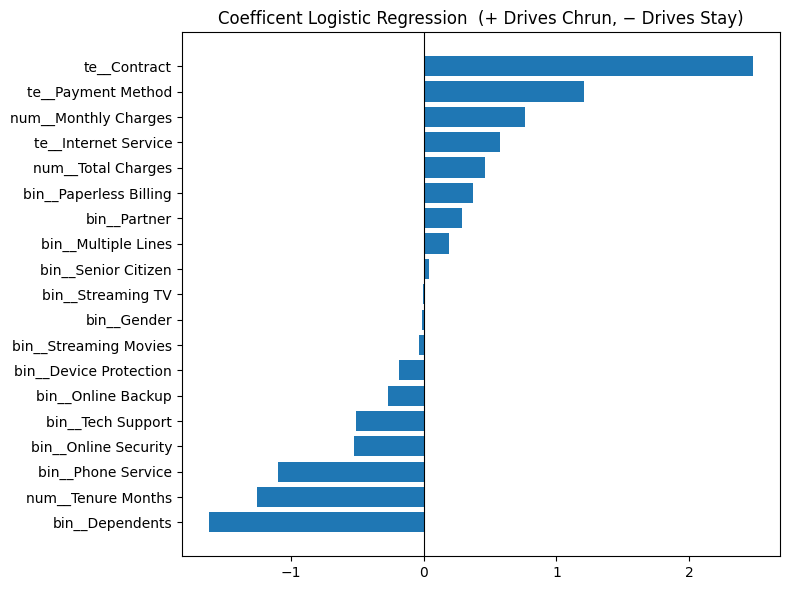

In [53]:
feat_names = best_model.named_steps['prep'].get_feature_names_out()
clf = best_model.named_steps['clf']

if hasattr(clf, 'coef_'):
    importance = clf.coef_[0]
    judul = 'Coefficent Logistic Regression  (+ Drives Chrun, − Drives Stay)'
elif hasattr(clf, 'feature_importances_'):
    importance = clf.feature_importances_
    judul = 'Feature Importance (impurity-based)'
else:
    importance = None

if importance is not None:
    fi = (pd.DataFrame({'feature': feat_names, 'importance': importance})
            .assign(abs_imp=lambda d: d['importance'].abs())
            .sort_values('abs_imp', ascending=False))
    display(fi[['feature', 'importance']].reset_index(drop=True))
    plt.figure(figsize=(8, 6))
    ordered = fi.sort_values('importance')
    plt.barh(ordered['feature'], ordered['importance'])
    plt.title(judul); plt.axvline(0, color='k', lw=0.8); plt.tight_layout(); plt.show()

,feature,importance
0,Tenure Months,0.218799
1,Monthly Charges,0.105483
2,Dependents,0.087549
3,Contract,0.086042
4,Phone Service,0.033183
5,Tech Support,0.025415
6,Online Security,0.015770
7,Paperless Billing,0.014441
8,Payment Method,0.009217
9,Internet Service,0.008650


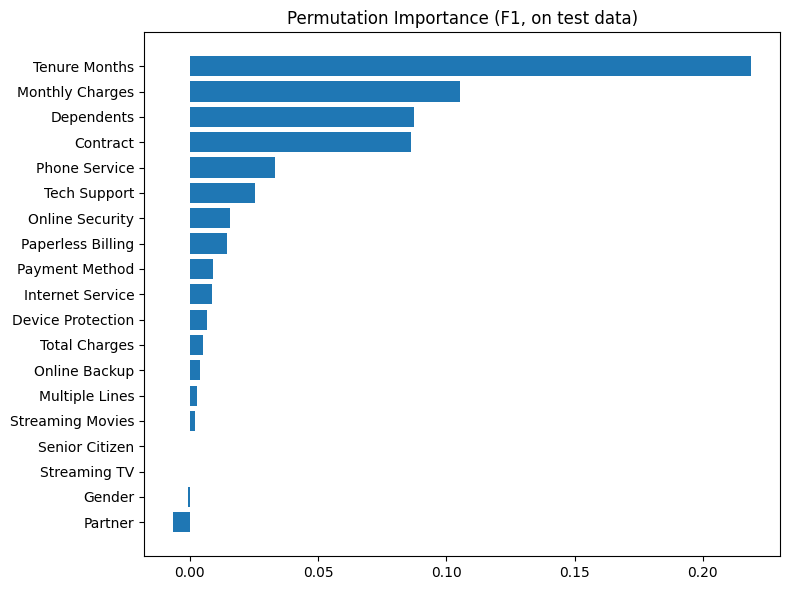

In [54]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(best_model, X_test, y_test, scoring='f1',
                              n_repeats=10, random_state=RANDOM_STATE)
pi = (pd.DataFrame({'feature': X_test.columns, 'importance': perm.importances_mean})
        .sort_values('importance', ascending=False).reset_index(drop=True))
display(pi)
plt.figure(figsize=(8, 6))
plt.barh(pi['feature'][::-1], pi['importance'][::-1])
plt.title('Permutation Importance (F1, on test data)'); plt.tight_layout(); plt.show()